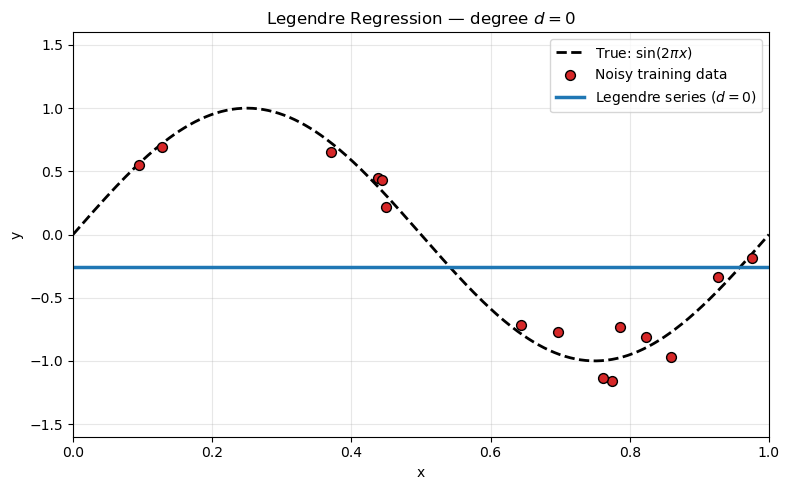

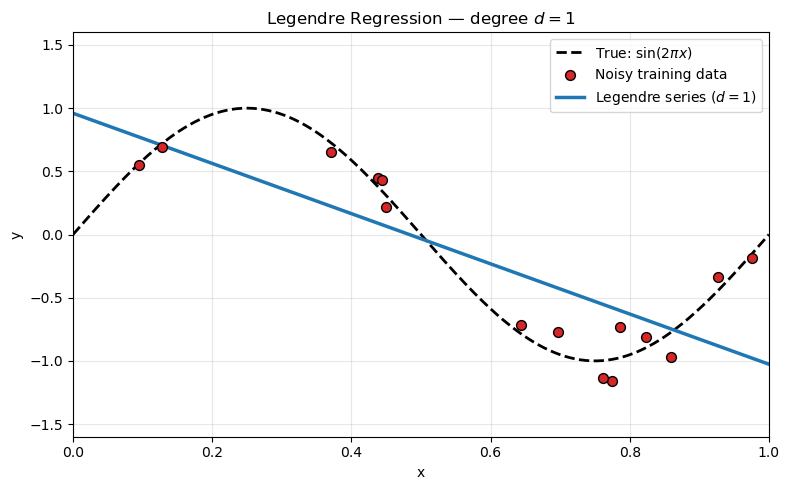

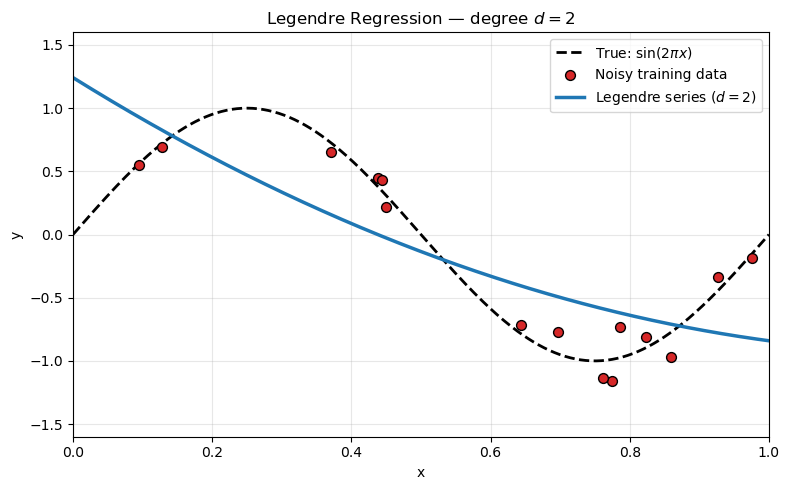

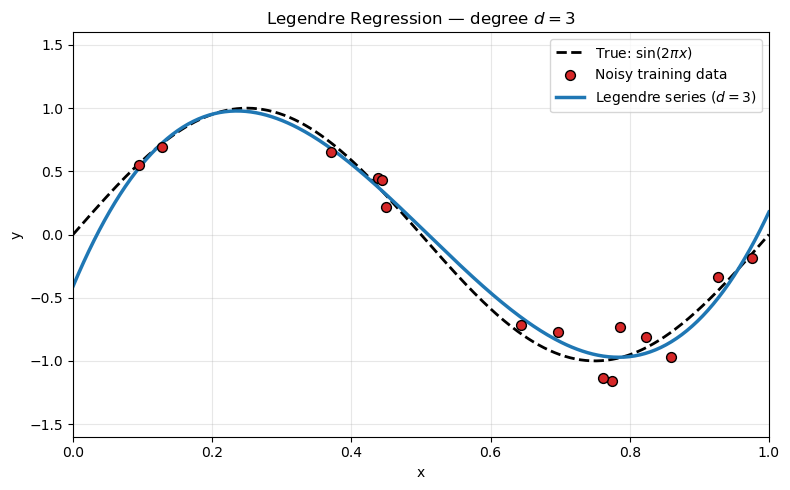

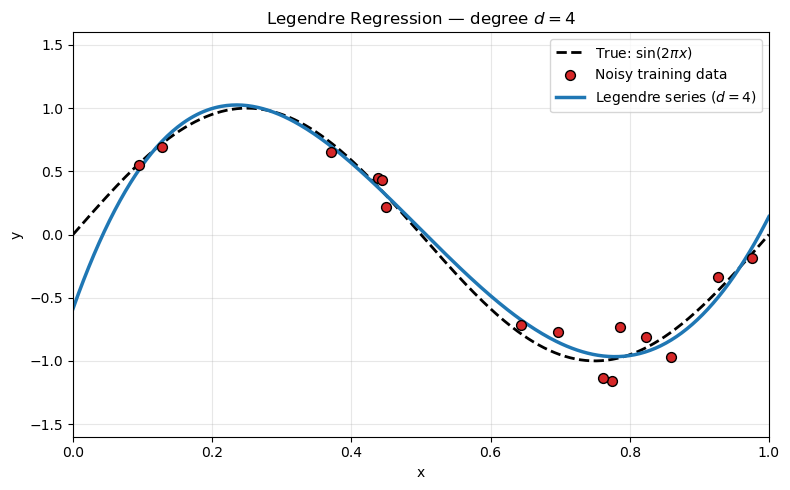

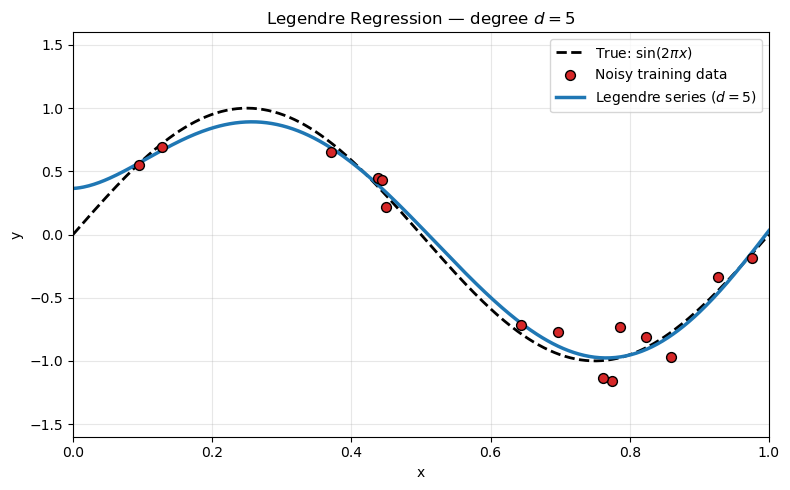

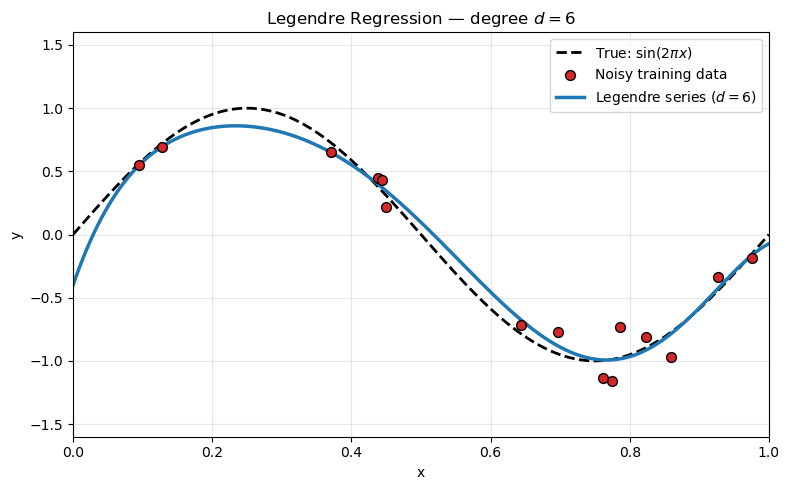

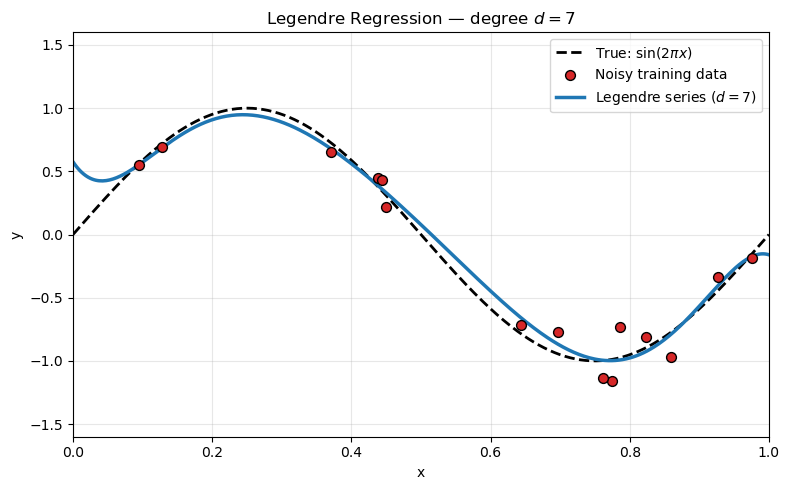

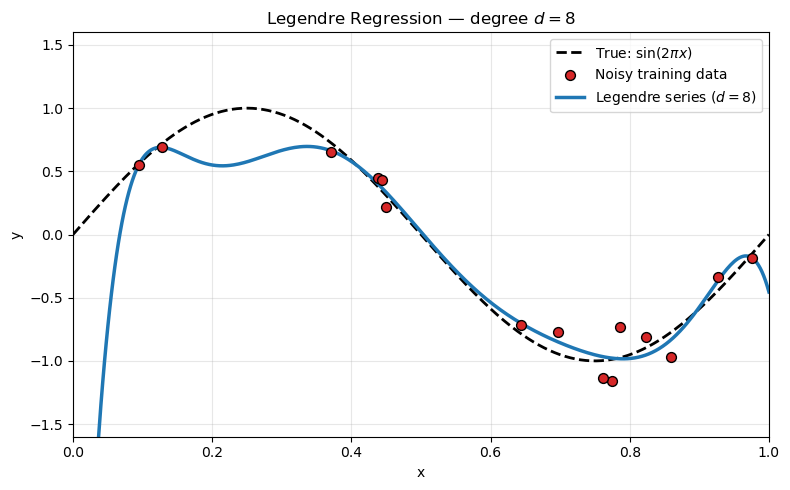

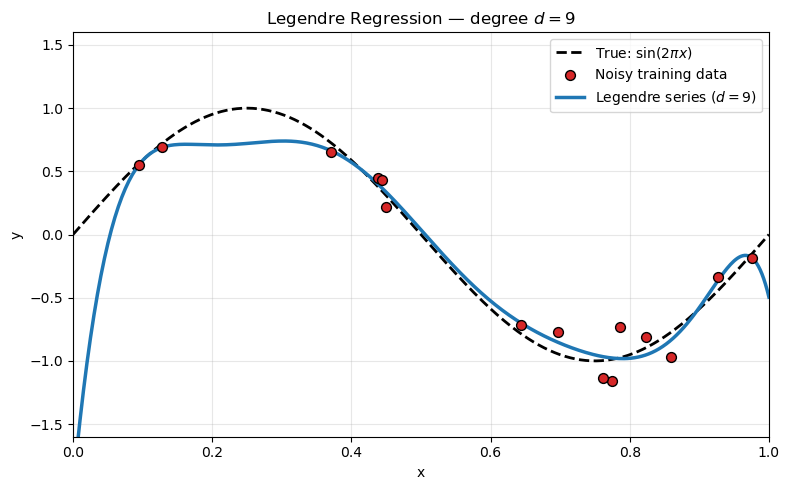

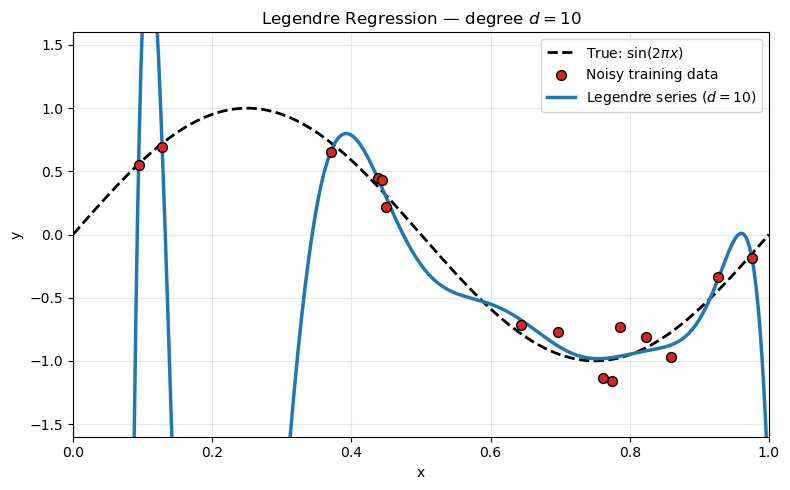

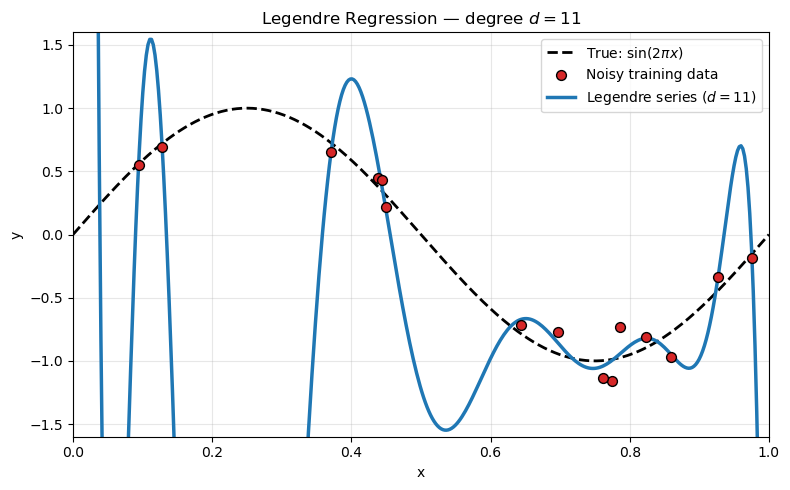

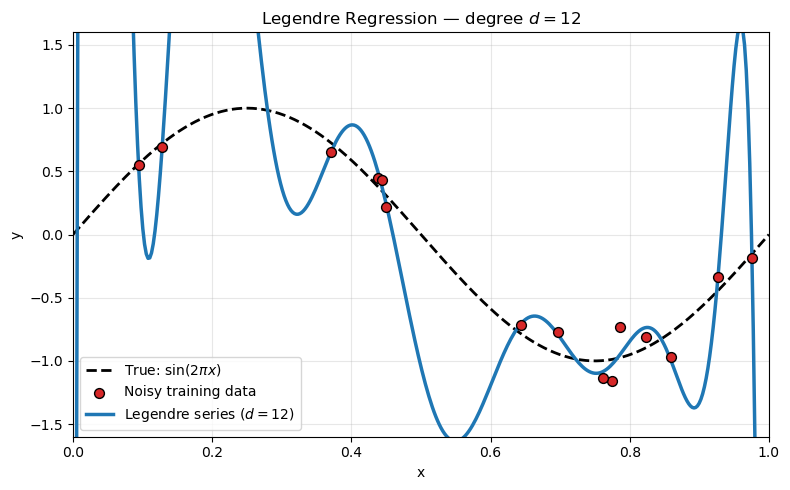

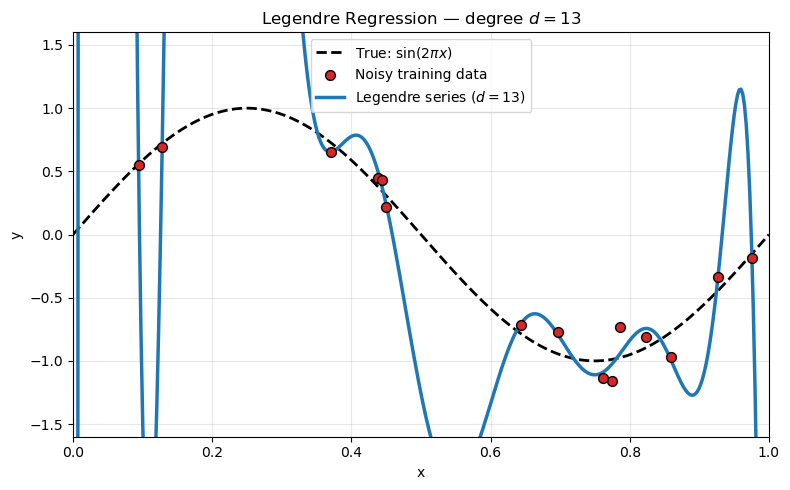

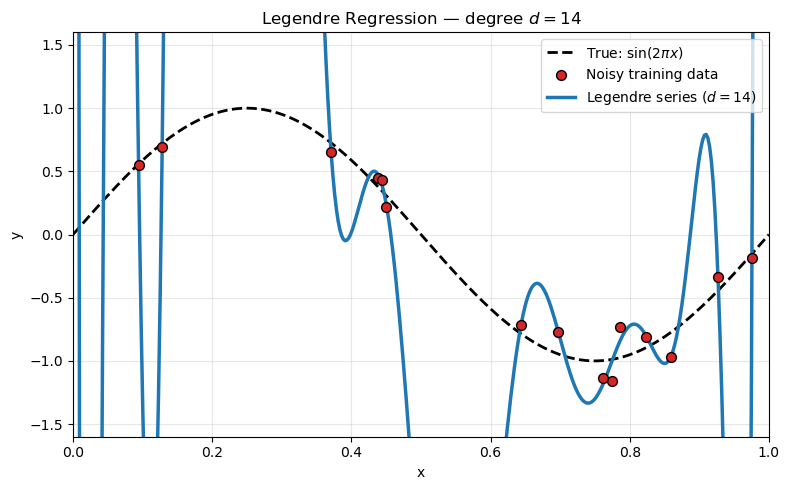

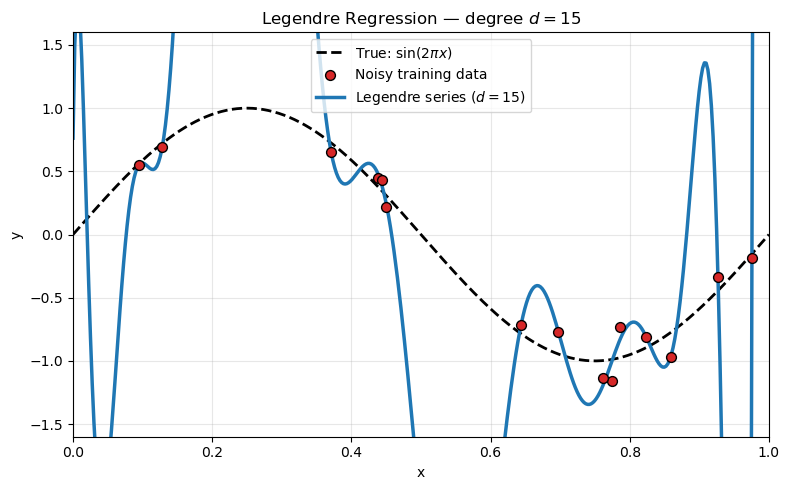

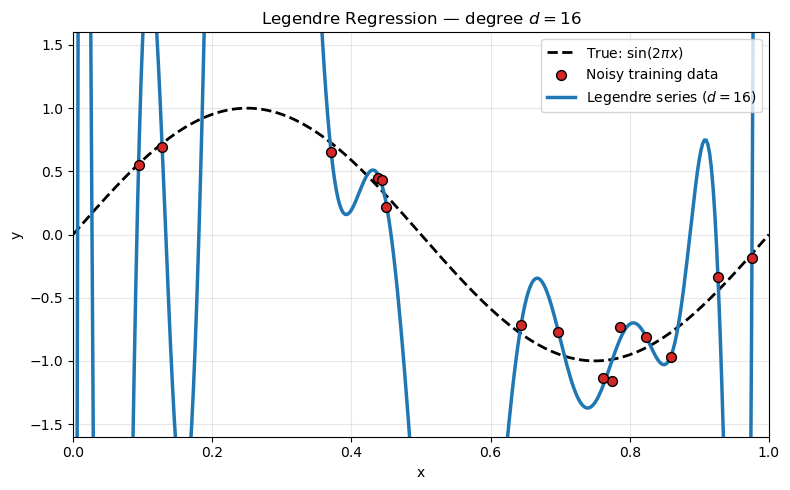

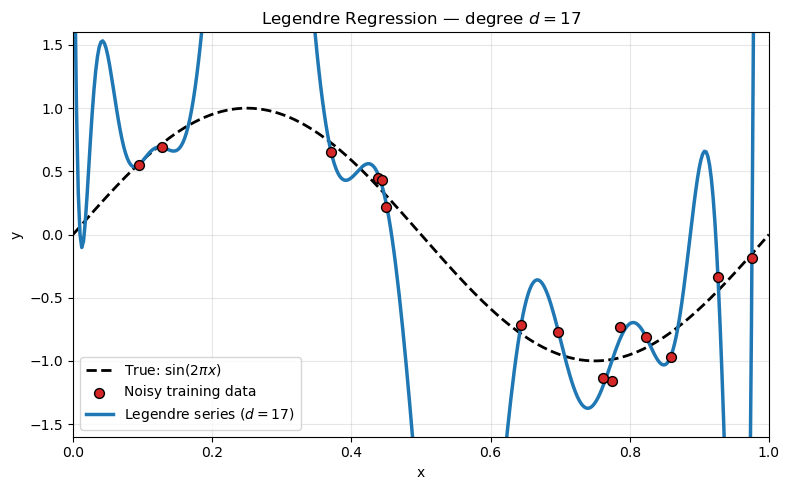

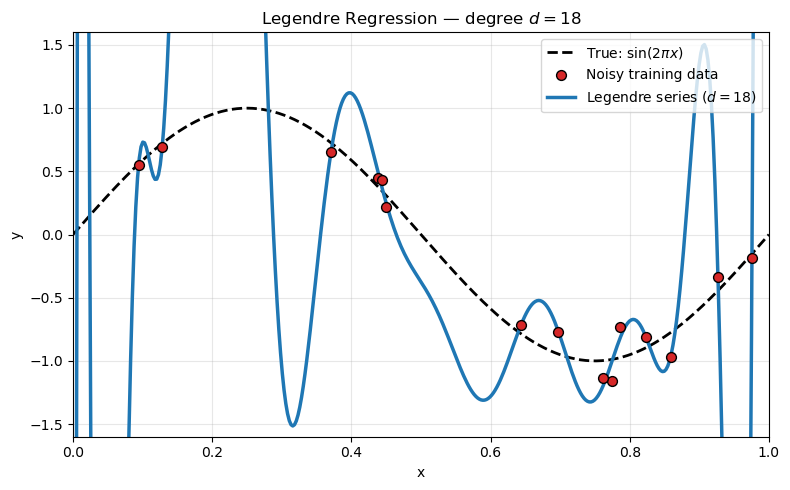

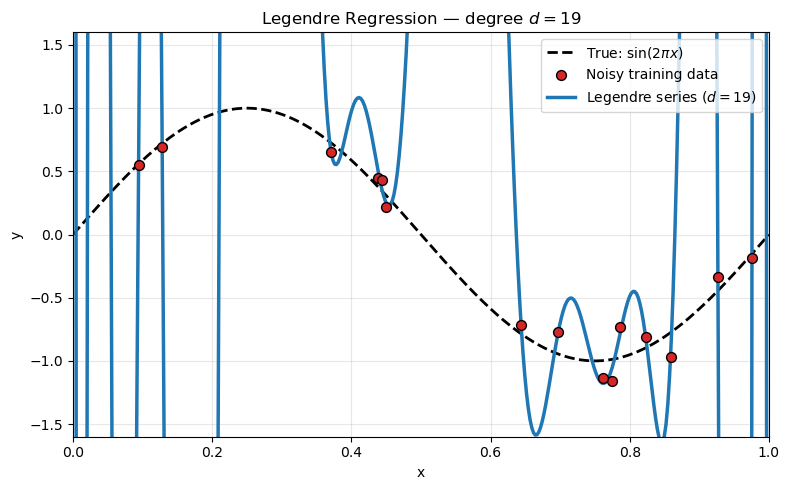

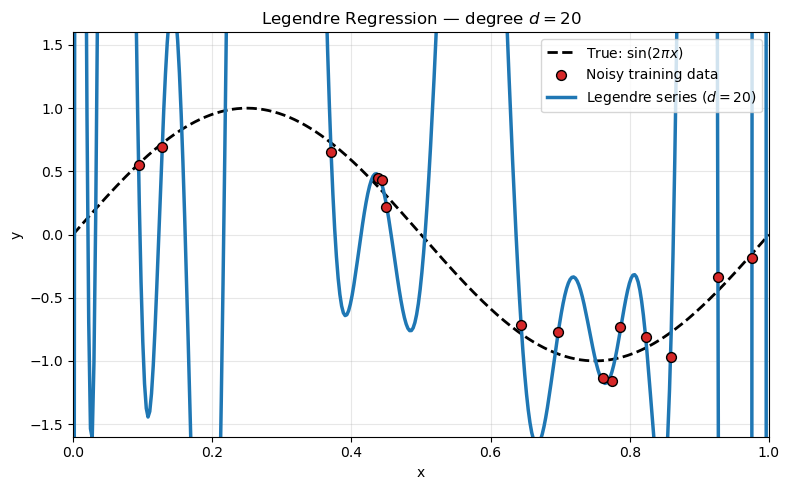

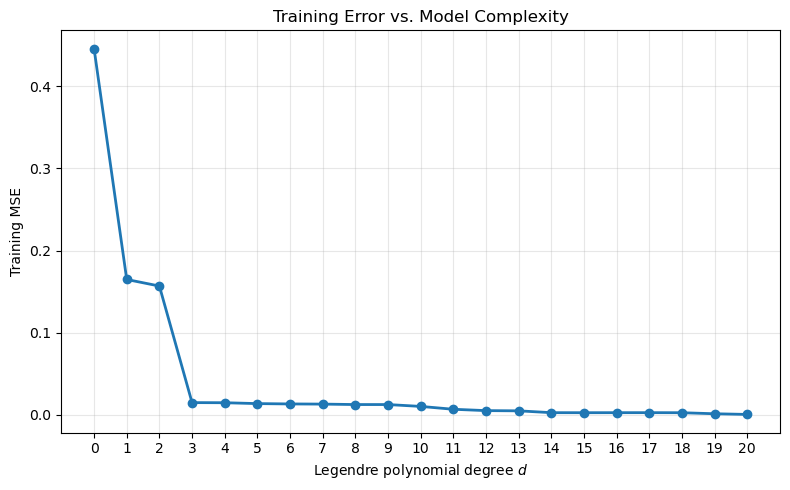

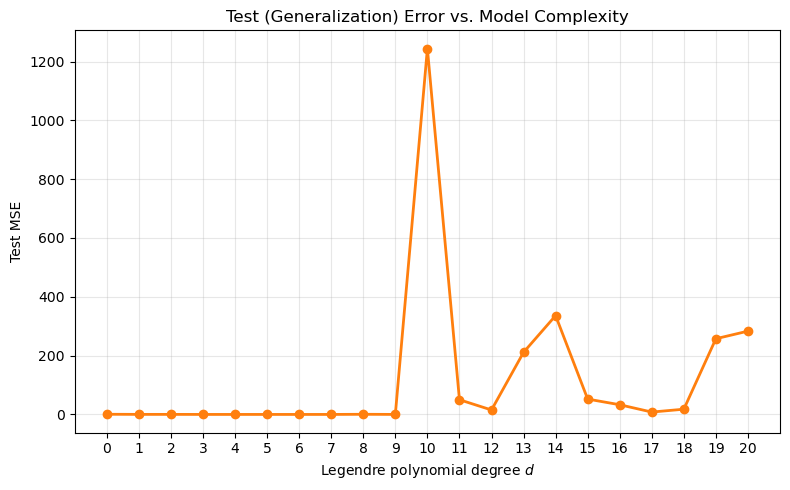

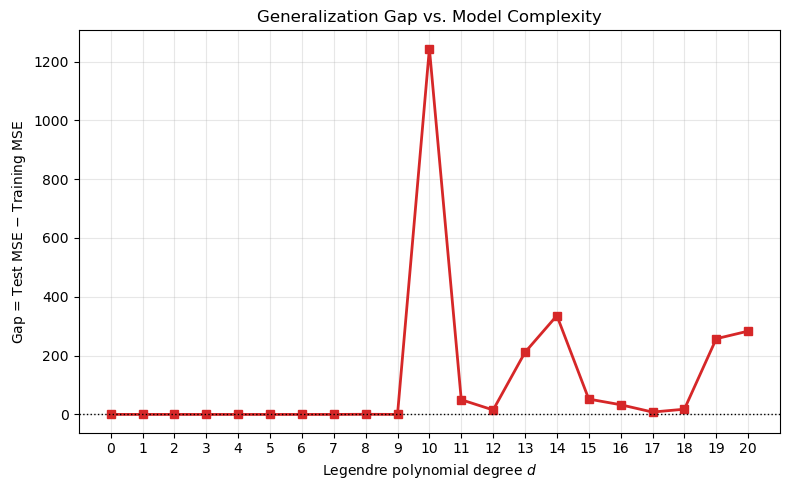

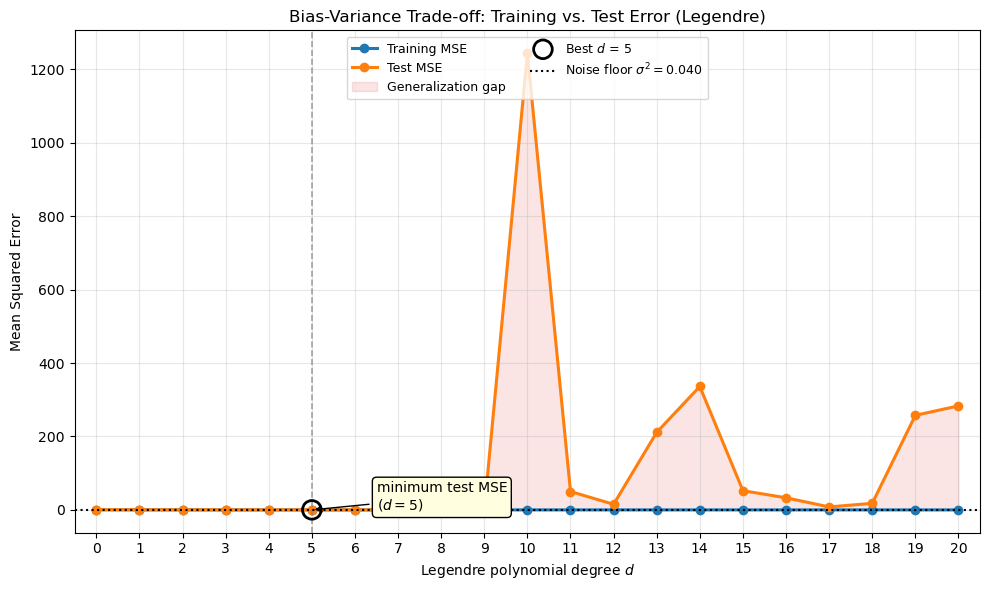

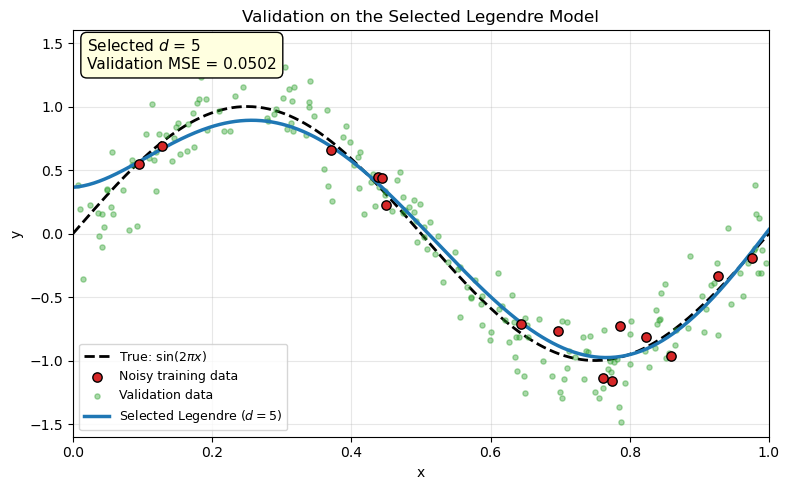


Legendre Regression — Model Complexity Report
   d |   Training MSE |     Test MSE
------------------------------------
   0 |        0.44582 |      0.62210
   1 |        0.16482 |      0.21603
   2 |        0.15682 |      0.22636
   3 |        0.01493 |      0.05085
   4 |        0.01479 |      0.05462
   5 |        0.01373 |      0.04729
   6 |        0.01332 |      0.05111
   7 |        0.01313 |      0.05038
   8 |        0.01258 |      0.51979
   9 |        0.01257 |      0.10963
  10 |        0.01031 |   1243.91900
  11 |        0.00683 |     50.05293
  12 |        0.00519 |     15.17478
  13 |        0.00492 |    211.24630
  14 |        0.00269 |    336.09994
  15 |        0.00264 |     52.25910
  16 |        0.00268 |     33.00824
  17 |        0.00270 |      8.08754
  18 |        0.00263 |     17.83705
  19 |        0.00137 |    257.48085
  20 |        0.00055 |    283.28612

  Selected d (lowest test MSE)      : 5
  Training MSE of selected model    : 0.01373
  Test MSE of s

In [1]:
# =============================================================================
# MODEL COMPLEXITY WITH LEGENDRE POLYNOMIALS
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting with a
# truncated Legendre polynomial expansion on a noisy sine wave.
#
# Model family:
#     y_hat(x) = sum_{k=0}^{d} w_k * P_k(t),    t = 2*x - 1 in [-1, 1]
#
# where P_k(t) is the Legendre polynomial of degree k. Legendre polynomials
# are orthogonal on [-1, 1]:
#     integral_{-1}^{1} P_j(t) P_k(t) dt = 2 / (2j + 1) * delta_{jk}
#
# Using this orthogonal basis (instead of raw powers x^k) makes the design
# matrix well-conditioned even for large degrees.
#
# Complexity is controlled by d, the maximum polynomial degree.
# We fit the linear coefficients with ridge-regularized least squares.
#
# Figures:
#   1. d individual fit plots for d = 0, 1, ..., d_max
#   2. Training MSE vs. d
#   3. Test MSE vs. d  (U-shaped)
#   4. Generalization gap = Test MSE - Training MSE
#   5. Combined training & test error
#   6. Validation on the selected model
#
# Console output:
#   Table of (d, training MSE, test MSE)
#   Best d, with train/test/validation MSE.
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

from numpy.polynomial.legendre import legvander, legval
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error


# =============================================================================
# 1. REPRODUCIBILITY AND CONFIG
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TRAIN = 15                # small training set -> visible under/overfitting
N_TEST = 200
N_VALID = 200

NOISE_SIGMA = 0.20
D_VALUES = list(range(0, 21))    # polynomial degree (complexity axis)


# =============================================================================
# 2. TRUE FUNCTION AND DATA GENERATION
# =============================================================================
def true_function(x):
    """Ground-truth: y = sin(2 * pi * x)."""
    return np.sin(2.0 * np.pi * x)


def to_legendre_domain(x):
    """Map x in [0, 1] to t in [-1, 1]."""
    return 2.0 * x - 1.0


def sample_points(n, rng):
    """Return n uniform samples on [0, 1] and their noisy targets."""
    x = rng.uniform(0.0, 1.0, size=n).reshape(-1, 1)
    y = true_function(x.ravel()) + rng.normal(0.0, NOISE_SIGMA, size=n)
    return x, y


X_train, y_train = sample_points(N_TRAIN, rng)
X_test, y_test = sample_points(N_TEST, rng)
X_valid, y_valid = sample_points(N_VALID, rng)

X_grid = np.linspace(0.0, 1.0, 400).reshape(-1, 1)
y_grid_true = true_function(X_grid.ravel())

# Map to Legendre domain [-1, 1]
T_train = to_legendre_domain(X_train)
T_test = to_legendre_domain(X_test)
T_valid = to_legendre_domain(X_valid)
T_grid = to_legendre_domain(X_grid)


# =============================================================================
# 3. LEGENDRE FEATURE MAP
# =============================================================================
def legendre_design_matrix(X, d):
    """Return the Legendre design matrix with columns
        [ P_0(t), P_1(t), ..., P_d(t) ],    t = 2*x - 1.
    Shape: (len(X), d + 1).
    """
    t = to_legendre_domain(X).ravel()
    return legvander(t, d)


# =============================================================================
# 4. FIT A LEGENDRE MODEL OF GIVEN COMPLEXITY d
# =============================================================================
def fit_legendre(d, alpha=1e-6):
    """Fit a Legendre expansion of degree d and return it plus train/test MSEs.

    Ridge with tiny alpha is a numerically safe OLS.
    """
    Phi_train = legendre_design_matrix(X_train, d)
    Phi_test = legendre_design_matrix(X_test, d)

    model = Ridge(alpha=alpha, fit_intercept=False)   # constant is P_0
    model.fit(Phi_train, y_train)

    y_train_pred = model.predict(Phi_train)
    y_test_pred = model.predict(Phi_test)

    mse_train = mean_squared_error(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)

    bundle = {
        "model": model,
        "d": d,
    }
    return bundle, mse_train, mse_test


def legendre_predict(bundle, X):
    """Predict with a fitted Legendre bundle on new inputs X."""
    Phi = legendre_design_matrix(X, bundle["d"])
    return bundle["model"].predict(Phi)


# =============================================================================
# 5. INDIVIDUAL FIT PLOT FOR EACH d
# =============================================================================
def plot_fit(d, bundle):
    y_grid_pred = legendre_predict(bundle, X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2, label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=50, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=rf"Legendre series ($d = {d}$)")

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(rf"Legendre Regression — degree $d = {d}$")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.savefig(f"legendre_fit_d_{d:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 6. FIT ALL COMPLEXITIES AND COLLECT ERRORS
# =============================================================================
def fit_all(d_values):
    results = {}
    for d in d_values:
        bundle, mse_train, mse_test = fit_legendre(d)
        results[d] = {
            "bundle": bundle,
            "mse_train": mse_train,
            "mse_test": mse_test,
        }
        plot_fit(d, bundle)
    return results


results = fit_all(D_VALUES)

Ds = np.array(D_VALUES)
mse_train = np.array([results[d]["mse_train"] for d in Ds])
mse_test = np.array([results[d]["mse_test"] for d in Ds])
gap = mse_test - mse_train


# =============================================================================
# 7. TRAINING ERROR vs. d
# =============================================================================
def plot_train_error(Ds, mse_train):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ds, mse_train, "-o", lw=2, color="tab:blue")
    ax.set_xlabel("Legendre polynomial degree $d$")
    ax.set_ylabel("Training MSE")
    ax.set_title("Training Error vs. Model Complexity")
    ax.set_xticks(Ds)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("legendre_training_error_vs_d.png", dpi=120)
    plt.show()


# =============================================================================
# 8. TEST ERROR vs. d
# =============================================================================
def plot_test_error(Ds, mse_test):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ds, mse_test, "-o", lw=2, color="tab:orange")
    ax.set_xlabel("Legendre polynomial degree $d$")
    ax.set_ylabel("Test MSE")
    ax.set_title("Test (Generalization) Error vs. Model Complexity")
    ax.set_xticks(Ds)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("legendre_test_error_vs_d.png", dpi=120)
    plt.show()


# =============================================================================
# 9. GENERALIZATION GAP
# =============================================================================
def plot_gap(Ds, gap):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ds, gap, "-s", lw=2, color="tab:red")
    ax.axhline(0.0, color="black", lw=1, linestyle=":")
    ax.set_xlabel("Legendre polynomial degree $d$")
    ax.set_ylabel(r"Gap = Test MSE $-$ Training MSE")
    ax.set_title("Generalization Gap vs. Model Complexity")
    ax.set_xticks(Ds)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("legendre_generalization_gap_vs_d.png", dpi=120)
    plt.show()


# =============================================================================
# 10. COMBINED TRAINING AND TEST ERROR
# =============================================================================
def plot_train_test_combined(Ds, mse_train, mse_test,
                             best_d=None, noise_sigma=None):
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(Ds, mse_train, "-o", lw=2.2, color="tab:blue",
            markersize=6, label="Training MSE")
    ax.plot(Ds, mse_test, "-o", lw=2.2, color="tab:orange",
            markersize=6, label="Test MSE")

    ax.fill_between(Ds, mse_train, mse_test,
                    where=(mse_test >= mse_train),
                    color="tab:red", alpha=0.12,
                    label="Generalization gap")
    ax.fill_between(Ds, mse_test, mse_train,
                    where=(mse_train > mse_test),
                    color="tab:green", alpha=0.12)

    if best_d is not None:
        best_idx = int(np.where(Ds == best_d)[0][0])
        ax.axvline(best_d, color="gray", lw=1.2, linestyle="--", alpha=0.7)
        ax.scatter([best_d], [mse_test[best_idx]],
                   s=180, facecolor="none", edgecolor="black",
                   linewidth=2, zorder=5, label=f"Best $d$ = {best_d}")
        ax.annotate(
            f"minimum test MSE\n($d = {best_d}$)",
            xy=(best_d, mse_test[best_idx]),
            xytext=(best_d + 1.5, mse_test[best_idx] + 0.03),
            fontsize=10,
            arrowprops=dict(arrowstyle="->", color="black", lw=1),
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor="lightyellow", edgecolor="black"),
        )

    if noise_sigma is not None:
        ax.axhline(noise_sigma ** 2, color="k", linestyle=":", lw=1.5,
                   label=rf"Noise floor $\sigma^2 = {noise_sigma**2:.3f}$")

    ax.set_xlim(-0.5, Ds.max() + 0.5)
    ax.set_xticks(Ds)
    ax.set_xlabel("Legendre polynomial degree $d$")
    ax.set_ylabel("Mean Squared Error")
    ax.set_title("Bias-Variance Trade-off: Training vs. Test Error (Legendre)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper center", ncol=2, fontsize=9)

    plt.tight_layout()
    plt.savefig("legendre_train_test_error_combined.png", dpi=120)
    plt.show()


# =============================================================================
# 11. VALIDATION ON THE SELECTED MODEL
# =============================================================================
def plot_validation(selected_d, bundle, mse_valid):
    y_grid_pred = legendre_predict(bundle, X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2,
            label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=45, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.scatter(X_valid, y_valid, s=14, c="tab:green", alpha=0.4,
               zorder=2, label="Validation data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=rf"Selected Legendre ($d = {selected_d}$)")

    ax.annotate(
        f"Selected $d$ = {selected_d}\n"
        f"Validation MSE = {mse_valid:.4f}",
        xy=(0.02, 0.98), xycoords="axes fraction",
        ha="left", va="top", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="lightyellow", edgecolor="black"),
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Validation on the Selected Legendre Model")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    plt.savefig("legendre_validation_selected_model.png", dpi=120)
    plt.show()


# =============================================================================
# 12. REPORTING
# =============================================================================
def print_table(Ds, mse_train, mse_test):
    header = f"{'d':>4} | {'Training MSE':>14} | {'Test MSE':>12}"
    print(header)
    print("-" * len(header))
    for d, mtr, mte in zip(Ds, mse_train, mse_test):
        print(f"{d:>4d} | {mtr:>14.5f} | {mte:>12.5f}")


def select_best_d(Ds, mse_test):
    idx = int(np.argmin(mse_test))
    return int(Ds[idx])


# =============================================================================
# 13. MAIN
# =============================================================================
def main():
    plot_train_error(Ds, mse_train)
    plot_test_error(Ds, mse_test)
    plot_gap(Ds, gap)

    best_d = select_best_d(Ds, mse_test)
    plot_train_test_combined(
        Ds, mse_train, mse_test,
        best_d=best_d,
        noise_sigma=NOISE_SIGMA,
    )

    best_bundle = results[best_d]["bundle"]
    y_valid_pred = legendre_predict(best_bundle, X_valid)
    mse_valid = mean_squared_error(y_valid, y_valid_pred)
    plot_validation(best_d, best_bundle, mse_valid)

    print()
    print("=" * 50)
    print("Legendre Regression — Model Complexity Report")
    print("=" * 50)
    print_table(Ds, mse_train, mse_test)

    print()
    print(f"  Selected d (lowest test MSE)      : {best_d}")
    print(f"  Training MSE of selected model    : {mse_train[best_d]:.5f}")
    print(f"  Test MSE of selected model        : {mse_test[best_d]:.5f}")
    print(f"  Validation MSE of selected model  : {mse_valid:.5f}")

    print()
    print("Educational interpretation:")
    print("  * Small d   -> underfitting (too few basis functions).")
    print("  * Mid d     -> good fit (Legendre basis tracks the sine).")
    print("  * Large d   -> overfitting (extra modes chase noise).")
    print("  * Gap grows with d, exactly like Fourier / RBF / raw polynomials.")


if __name__ == "__main__":
    main()